# 09 Simpson's Check

**Question:** Does any result flip when split by segment?

Task 2, step 9: **check for Simpson's paradox: compare one aggregate result with the same comparison split by segment.**

**Simpson's paradox:** a comparison can point one way in the aggregate and the *opposite* way inside every subgroup. It happens when the two groups have a **different mix** of subgroups that themselves differ a lot. For example, if exchange 2 sells mostly to a low-CTR campaign, exchange 2 looks worse overall even if it beats exchange 1 *within* every campaign. The aggregate then answers *"which group happened to buy better inventory?"*, not *"which is better?"*.

Two scans, both on CTR:
1. **Segments, pooled vs within campaign:** for each dimension, take its two largest segments and compare their CTR across all campaigns pooled, then within each campaign. Campaigns are the strongest confounder here: their CTRs differ a lot, and so does their mix of exchanges, slots and regions.
2. **Campaigns, overall vs within segment:** for each pair of campaigns, compare their overall CTR, then compare them within the segments of each dimension. This is the challenge's example: *how a campaign can look better in every segment yet worse overall*.

**The within-group answer** is a **Mantel–Haenszel weighted difference**: each subgroup's difference, weighted by `n_A·n_B/(n_A + n_B)`. It is tested with the **Cochran–Mantel–Haenszel** test. A **reversal** is when the aggregate and the within-group differences have **opposite signs**, and it counts as *significant* when both sides are significant (p < 0.05).

The setup and segment aggregation are the same as Notebook 05. The database is opened read-only.

### Setup

In [1]:
# CELL 1: setup (read-only connection)
from pathlib import Path
import math, os, re, shutil, signal, time
import duckdb
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

KILL_STALE = False
RUN_WIN_RATE = True          # win rate needs one pass over the 53M bids (a few minutes)
FOCUS = 1458                 # the campaign shown in detail; change to any advertiser_id
MIN_EXPECTED_CLICKS = 30     # CTR shown when imps >= this / overall CTR
MIN_CLICKS_CVR, MIN_CONVS_CPA, MIN_BIDS_WR = 30, 10, 1_000
TOP_TAGS = 30                # user tags shown (by volume)
PROJECT_ROOT = Path.cwd().parent
# Where the data comes from (the views raw_* and typed_* are the same either way):
#   1. data/processed/ipinyou.duckdb, the database the loading notebook built, if it is still there
#   2. otherwise the pipeline's hourly Parquet files in data/interim, read in memory (pipeline_views.py)
DB_PATH = PROJECT_ROOT / "data" / "processed" / "ipinyou.duckdb"
BID_DIR = PROJECT_ROOT / "data" / "interim" / "bid_parquet"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"

if "con" in globals():
    try:
        con.close()
    except Exception:
        pass

def open_db(path, kill_stale=False, retries=5):
    for attempt in range(retries):
        try:
            return duckdb.connect(str(path), read_only=True)
        except duckdb.IOException as e:
            m = re.search(r"PID (\d+)", str(e))
            if "lock" not in str(e).lower() or m is None:
                raise
            print(f"The database is locked by another Python process (PID {m.group(1)}).")
            if not kill_stale:
                print("Shut down the other notebook (Jupyter > Running tab > Shut Down), "
                      "or set KILL_STALE = True and run this cell again.")
                raise
            os.kill(int(m.group(1)), signal.SIGTERM)
            time.sleep(2)
    raise RuntimeError("Could not get the database lock")

if DB_PATH.exists():
    con = open_db(DB_PATH, kill_stale=KILL_STALE)
    DATA_SOURCE = f"{DB_PATH.name} (the loading notebook's database)"
else:
    from pipeline_views import create_views
    con = duckdb.connect()   # in memory: reads the Parquet files, writes nothing to disk
    DATA_SOURCE = create_views(con, PROJECT_ROOT)
con.execute("SET preserve_insertion_order=false")
try:
    con.execute("SET enable_progress_bar=false")
except Exception:
    pass
q = lambda sql: con.execute(sql).df()

views = set(q("SELECT view_name FROM duckdb_views() WHERE NOT internal")["view_name"])
assert {"typed_imp", "typed_clk", "typed_conv"} <= views, "Run the loading cells first"
if "typed_bid" not in views:
    files = [str(p) for p in sorted(BID_DIR.glob("bid_*.parquet"))]
    files += [str(p) for p in sorted(BID_DIR.glob("bid_*/part_*.parquet")) if not p.parent.name.endswith(".partial")]
    t = lambda c, typ="BIGINT": f"TRY_CAST(nullif(nullif({c}, ''), 'null') AS {typ}) AS {c}"
    con.execute("CREATE TEMP VIEW typed_bid AS SELECT " + ", ".join(
        [t(c) for c in ["advertiser_id", "region", "ad_exchange", "ad_slot_width", "ad_slot_height",
                        "ad_slot_visibility", "ad_slot_format", "ad_slot_floor_price"]] + ["user_agent", "user_tags"])
        + " FROM read_parquet([" + ", ".join(f"'{x}'" for x in files) + "])")
    print("typed_bid rebuilt in memory from", len(files), "Parquet files")

# optional readable names, if the dataset's lookup files are anywhere under data/
def lookup(name):
    for p in (PROJECT_ROOT / "data").rglob(name):
        d = {}
        for line in p.read_text(encoding="utf-8", errors="replace").splitlines():
            parts = line.split("\t")
            if len(parts) >= 2 and parts[0].strip().lstrip("-").isdigit():
                d[parts[0].strip()] = parts[1].strip()
        return d
    return {}
REGION_NAMES, TAG_NAMES = lookup("region.en.txt"), lookup("user.profile.tags.en.txt")
print("region names:", "found" if REGION_NAMES else "not found (codes shown)",
      "| tag names:", "found" if TAG_NAMES else "not found (codes shown)")

def wilson(k, n, z=1.959964):
    k, n = np.asarray(k, float), np.asarray(n, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = k / n
        d = 1 + z**2 / n
        c = (p + z**2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return np.where(n > 0, c - h, np.nan), np.where(n > 0, c + h, np.nan)

def ztest(k1, n1, k2, n2):
    """Two-proportion z-test (pooled), two-sided p-value. Returns (z, p)."""
    p1, p2, pp = k1 / n1, k2 / n2, (k1 + k2) / (n1 + n2)
    se = math.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
    if se == 0:
        return np.nan, np.nan
    z = (p1 - p2) / se
    return z, math.erfc(abs(z) / math.sqrt(2))

def bh(p):
    """Benjamini-Hochberg q-values (NaN stays NaN)."""
    p = np.asarray(p, float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    if ok.sum():
        pv = p[ok]
        o = np.argsort(pv)
        r = pv[o] * ok.sum() / np.arange(1, ok.sum() + 1)
        r = np.minimum.accumulate(r[::-1])[::-1]
        res = np.empty_like(pv)
        res[o] = np.clip(r, 0, 1)
        out[ok] = res
    return out

try:
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mt
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                         "grid.color": "#e6e5e0", "axes.titlesize": 10, "axes.titleweight": "bold",
                         "axes.titlelocation": "left", "font.size": 9})
except ImportError:
    plt = None
BLUE, ORANGE, GREY, INK2 = "#2a78d6", "#eb6834", "#8a8984", "#52514e"

def save(fig, name):
    try:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    except OSError:
        print(f"(no disk space: {name}.png not saved)")
print("Data:", DATA_SOURCE)
RUN_WIN_RATE = False   # CTR only here: no need to read the bids

region names: found | tag names: found
Data: ipinyou.duckdb (the loading notebook's database)


### 1. Device, OS and browser from the user agent

In [2]:
# CELL 2: user-agent lookup
t0 = time.time()
ua_src = "SELECT DISTINCT user_agent FROM typed_imp" + (" UNION SELECT DISTINCT user_agent FROM typed_bid" if RUN_WIN_RATE else "")
con.execute(f"""
CREATE OR REPLACE TEMP TABLE ua_map AS
WITH u AS ({ua_src}), l AS (SELECT user_agent, lower(coalesce(user_agent, '')) AS ua FROM u)
SELECT user_agent,
  CASE WHEN ua = '' THEN 'unknown'
       WHEN regexp_matches(ua, 'ipad|tablet') THEN 'tablet'
       WHEN regexp_matches(ua, 'mobile|android|iphone|ipod|windows phone|symbian|blackberry|nokia|ucweb|opera mini|midp') THEN 'mobile'
       ELSE 'desktop' END AS device,
  CASE WHEN ua = '' THEN 'unknown'
       WHEN regexp_matches(ua, 'iphone|ipad|ipod') THEN 'iOS'
       WHEN regexp_matches(ua, 'android') THEN 'Android'
       WHEN regexp_matches(ua, 'windows nt 5\\.1|windows xp') THEN 'Windows XP'
       WHEN regexp_matches(ua, 'windows nt 6\\.1') THEN 'Windows 7'
       WHEN regexp_matches(ua, 'windows nt 6\\.[23]') THEN 'Windows 8'
       WHEN regexp_matches(ua, 'windows nt 6\\.0') THEN 'Windows Vista'
       WHEN regexp_matches(ua, 'windows') THEN 'Windows (other)'
       WHEN regexp_matches(ua, 'mac os|macintosh') THEN 'macOS'
       WHEN regexp_matches(ua, 'linux') THEN 'Linux'
       ELSE 'other' END AS os,
  CASE WHEN ua = '' THEN 'unknown'
       WHEN regexp_matches(ua, 'metasr|sogou') THEN 'Sogou'
       WHEN regexp_matches(ua, '360se|360ee|360browser') THEN '360'
       WHEN regexp_matches(ua, 'maxthon') THEN 'Maxthon'
       WHEN regexp_matches(ua, 'theworld') THEN 'TheWorld'
       WHEN regexp_matches(ua, 'qqbrowser|tencenttraveler') THEN 'QQ'
       WHEN regexp_matches(ua, 'ucbrowser|ucweb') THEN 'UC'
       WHEN regexp_matches(ua, 'opera|opr/') THEN 'Opera'
       WHEN regexp_matches(ua, 'chrome|crios') THEN 'Chrome'
       WHEN regexp_matches(ua, 'firefox') THEN 'Firefox'
       WHEN regexp_matches(ua, 'msie|trident') THEN 'IE'
       WHEN regexp_matches(ua, 'safari') THEN 'Safari'
       ELSE 'other' END AS browser
FROM l""")
n_ua = q("SELECT count(*) AS n FROM ua_map").n[0]
print(f"{n_ua:,} distinct user agents parsed ({time.time() - t0:.0f}s)")
display(q("""SELECT device, os, browser, count(*) AS distinct_strings FROM ua_map GROUP BY ALL
             ORDER BY distinct_strings DESC LIMIT 12"""))

459,647 distinct user agents parsed (1s)


,device,os,browser,distinct_strings
0,desktop,Windows XP,IE,222238
1,desktop,Windows 7,IE,53816
2,desktop,Windows XP,QQ,28571
3,desktop,Windows XP,Sogou,27296
4,desktop,Windows 7,Sogou,15969
5,mobile,Android,Safari,12905
6,desktop,Windows XP,360,11551
7,tablet,Windows 7,IE,10454
8,desktop,Windows XP,TheWorld,8406
9,desktop,Windows 7,QQ,7302


### 2. Link clicks and conversions (the Notebook 02 rule)

In [3]:
# CELL 3: linking -> flags per impression
con.execute("""
CREATE OR REPLACE TEMP TABLE imp_c AS
SELECT DISTINCT bid_id, ipinyou_id, timestamp AS imp_ts, hash(bid_id, ipinyou_id, timestamp) AS imp_key
FROM typed_imp WHERE bid_id IN (SELECT bid_id FROM typed_clk UNION SELECT bid_id FROM typed_conv)""")
for log in ["clk", "conv"]:
    con.execute(f"""
    CREATE OR REPLACE TEMP TABLE {log}_m AS
    WITH e AS (SELECT row_number() OVER () AS ev_id, bid_id, ipinyou_id, timestamp AS ev_ts
               FROM (SELECT DISTINCT * FROM typed_{log})),
    m1 AS (SELECT e.ev_id, i.imp_key FROM e ASOF JOIN imp_c i
           ON e.bid_id = i.bid_id AND e.ipinyou_id = i.ipinyou_id AND e.ev_ts >= i.imp_ts),
    m2 AS (SELECT e.ev_id, i.imp_key FROM e ASOF JOIN imp_c i ON e.bid_id = i.bid_id AND e.ev_ts >= i.imp_ts),
    m3 AS (SELECT e.ev_id, arg_min(i.imp_key, abs(epoch(e.ev_ts) - epoch(i.imp_ts))) AS imp_key
           FROM e JOIN imp_c i USING (bid_id) GROUP BY 1)
    SELECT coalesce(m1.imp_key, m2.imp_key, m3.imp_key) AS imp_key
    FROM e LEFT JOIN m1 USING (ev_id) LEFT JOIN m2 USING (ev_id) LEFT JOIN m3 USING (ev_id)""")
con.execute("""
CREATE OR REPLACE TEMP TABLE flags AS
WITH k AS (SELECT DISTINCT imp_key FROM clk_m WHERE imp_key IS NOT NULL),
     v AS (SELECT DISTINCT imp_key FROM conv_m WHERE imp_key IS NOT NULL)
SELECT coalesce(k.imp_key, v.imp_key) AS imp_key, (k.imp_key IS NOT NULL)::INT AS clicked,
       (v.imp_key IS NOT NULL)::INT AS converted, (k.imp_key IS NOT NULL AND v.imp_key IS NOT NULL)::INT AS pc_converted
FROM k FULL JOIN v USING (imp_key)""")
display(q("SELECT sum(clicked) AS clicked_imps, sum(converted) AS converted_imps, sum(pc_converted) AS postclick_converted FROM flags"))

,clicked_imps,converted_imps,postclick_converted
0,8751.0,391.0,391.0


### 3. Segment aggregates (pooled and per campaign)

In [4]:
# CELL 4: segment aggregates
DIMS = {   # dimension -> SQL expression (same in the impression and bid logs)
    "region": "CAST(region AS VARCHAR)",
    "ad_exchange": "CAST(ad_exchange AS VARCHAR)",
    "slot_size": "CAST(ad_slot_width AS VARCHAR) || 'x' || CAST(ad_slot_height AS VARCHAR)",
    "slot_visibility": "CAST(ad_slot_visibility AS VARCHAR)",
    "slot_format": "CAST(ad_slot_format AS VARCHAR)",
    "floor_band": """CASE WHEN ad_slot_floor_price = 0 THEN 'a: 0' WHEN ad_slot_floor_price <= 10 THEN 'b: 1-10'
                          WHEN ad_slot_floor_price <= 50 THEN 'c: 11-50' WHEN ad_slot_floor_price <= 100 THEN 'd: 51-100'
                          WHEN ad_slot_floor_price <= 200 THEN 'e: 101-200' ELSE 'f: 200+' END""",
    "device": "u.device", "os": "u.os", "browser": "u.browser",
}

def grouped(source, measures, extra_from=""):
    sel = ", ".join(f"{expr} AS {d}" for d, expr in DIMS.items())
    sets = ", ".join(f"(advertiser_id, {d}), ({d})" for d in DIMS)
    gcols = ", ".join(f"GROUPING({d}) AS g_{d}" for d in DIMS)
    return q(f"""
        WITH s AS (SELECT advertiser_id, {sel}, {measures['row']}
                   FROM {source} {extra_from})
        SELECT advertiser_id, {", ".join(DIMS)}, GROUPING(advertiser_id) AS g_adv, {gcols}, {measures['agg']}
        FROM s GROUP BY GROUPING SETS ({sets})""")

def to_long(df, value_cols):
    out = []
    for d in DIMS:
        part = df[df[f"g_{d}"] == 0]
        out.append(pd.DataFrame({"scope": np.where(part.g_adv == 0, part.advertiser_id.astype("Int64").astype(str), "ALL"),
                                 "dimension": d, "segment": part[d].fillna("NULL").astype(str).values,
                                 **{c: part[c].values for c in value_cols}}))
    return pd.concat(out, ignore_index=True)

t0 = time.time()
imp_agg = grouped(
    "typed_imp i",
    {"row": "coalesce(f.clicked, 0) AS clicked, coalesce(f.converted, 0) AS converted, "
            "coalesce(f.pc_converted, 0) AS pc_converted, paying_price / 1000.0 AS cost",
     "agg": "count(*) AS imps, sum(clicked) AS clicks, sum(converted) AS convs, sum(pc_converted) AS pc_convs, sum(cost) AS spend"},
    "LEFT JOIN flags f ON f.imp_key = hash(i.bid_id, i.ipinyou_id, i.timestamp) LEFT JOIN ua_map u USING (user_agent)")
seg = to_long(imp_agg, ["imps", "clicks", "convs", "pc_convs", "spend"])
print(f"impression segments: {len(seg):,} rows ({time.time() - t0:.0f}s)")

if RUN_WIN_RATE:
    t0 = time.time()
    bid_agg = grouped("typed_bid b", {"row": "1 AS one", "agg": "count(*) AS bids"},
                      "LEFT JOIN ua_map u USING (user_agent)")
    seg = seg.merge(to_long(bid_agg, ["bids"]), on=["scope", "dimension", "segment"], how="left")
    print(f"bid segments added ({time.time() - t0:.0f}s)")
else:
    seg["bids"] = np.nan

# user tags (impressions only; the bid log has no user tags in Season 2, see Notebook 01)
t0 = time.time()
tags = q("""
    WITH t AS (SELECT i.advertiser_id, unnest(string_split(i.user_tags, ',')) AS tag,
                      coalesce(f.clicked, 0) AS clicked, coalesce(f.converted, 0) AS converted,
                      coalesce(f.pc_converted, 0) AS pc_converted, i.paying_price / 1000.0 AS cost
               FROM typed_imp i LEFT JOIN flags f ON f.imp_key = hash(i.bid_id, i.ipinyou_id, i.timestamp)
               WHERE i.user_tags IS NOT NULL)
    SELECT advertiser_id, tag, GROUPING(advertiser_id) AS g_adv, count(*) AS imps, sum(clicked) AS clicks,
           sum(converted) AS convs, sum(pc_converted) AS pc_convs, sum(cost) AS spend
    FROM t GROUP BY GROUPING SETS ((advertiser_id, tag), (tag))""")
tags = pd.DataFrame({"scope": np.where(tags.g_adv == 0, tags.advertiser_id.astype("Int64").astype(str), "ALL"),
                     "dimension": "user_tag", "segment": tags.tag.astype(str),
                     **{c: tags[c].values for c in ["imps", "clicks", "convs", "pc_convs", "spend"]}, "bids": np.nan})
top = tags[tags.scope == "ALL"].nlargest(TOP_TAGS, "imps").segment
seg = pd.concat([seg, tags[tags.segment.isin(top)]], ignore_index=True)
print(f"user tags: {tags.segment.nunique()} distinct, top {TOP_TAGS} kept ({time.time() - t0:.0f}s)")

# scope totals (for 'vs the rest' and the shares)
totals = q("""SELECT CAST(advertiser_id AS VARCHAR) AS scope, count(*) AS imps,
                     sum(coalesce(f.clicked, 0)) AS clicks, sum(paying_price) / 1000.0 AS spend
              FROM typed_imp i LEFT JOIN flags f ON f.imp_key = hash(i.bid_id, i.ipinyou_id, i.timestamp)
              GROUP BY ROLLUP (advertiser_id)""")
totals["scope"] = totals.scope.fillna("ALL")
totals = totals.set_index("scope")
display(totals.style.format({"imps": "{:,.0f}", "clicks": "{:,.0f}", "spend": "{:,.0f}"}))

impression segments: 542 rows (1s)
user tags: 43 distinct, top 30 kept (1s)


,imps,clicks,spend
scope,,,
3427,"2,593,765","1,909","210,240"
ALL,"12,237,087","8,751","958,739"
1458,"3,083,056","2,434","212,400"
3476,"1,970,360","1,023","156,088"
3386,"2,847,802","2,062","219,067"
3358,"1,742,104","1,323","160,943"


In [5]:
# CELL 5: metrics per segment
S = seg.copy()
for c in ["imps", "clicks", "convs", "pc_convs"]:
    S[c] = S[c].fillna(0).astype("int64")
S["imp_share"] = S.imps / S.scope.map(totals.imps)
S["ctr"] = S.clicks / S.imps
S["ctr_lo"], S["ctr_hi"] = wilson(S.clicks, S.imps)
S["cvr"] = S.pc_convs / S.clicks.where(S.clicks > 0)
S["cvr_lo"], S["cvr_hi"] = wilson(S.pc_convs, S.clicks)
S["cpa"] = S.spend / S.convs.where(S.convs > 0)
S["cpm"] = 1000 * S.spend / S.imps
S["cpc"] = S.spend / S.clicks.where(S.clicks > 0)
S["win_rate"] = S.imps / S.bids.where(S.bids > 0)
S["win_rate_lo"], S["win_rate_hi"] = wilson(S.imps, S.bids)

# minimum volume, per scope (each campaign has its own CTR)
scope_ctr = totals.clicks / totals.imps
S["min_imps"] = np.ceil(MIN_EXPECTED_CLICKS / S.scope.map(scope_ctr))
S["show_ctr"] = S.imps >= S.min_imps
S["show_cvr"] = S.clicks >= MIN_CLICKS_CVR
S["show_cpa"] = S.convs >= MIN_CONVS_CPA
S["show_wr"] = S.bids >= MIN_BIDS_WR

# segment vs the rest of its scope (CTR), then Benjamini-Hochberg over every test run
res = [ztest(r.clicks, r.imps, totals.clicks[r.scope] - r.clicks, totals.imps[r.scope] - r.imps)
       if r.show_ctr and 0 < r.imps < totals.imps[r.scope] else (np.nan, np.nan) for r in S.itertuples()]
S["z_vs_rest"], S["p_vs_rest"] = [x[0] for x in res], [x[1] for x in res]
rest_ctr = (S.scope.map(totals.clicks) - S.clicks) / (S.scope.map(totals.imps) - S.imps)
S["ctr_lift_vs_rest"] = S.ctr / rest_ctr - 1
S["q_vs_rest"] = bh(S.p_vs_rest)
S["significant"] = S.q_vs_rest < 0.05

S["label"] = [f"{s} · {REGION_NAMES.get(s, '')}" if d == "region" and s in REGION_NAMES else
              (f"{s} · {TAG_NAMES.get(s, '')}" if d == "user_tag" and s in TAG_NAMES else s)
              for d, s in zip(S.dimension, S.segment)]

n_tests = int(S.p_vs_rest.notna().sum())
mc = pd.DataFrame({"tests run": [int(n_tests)], "p < 0.05 (uncorrected)": [int((S.p_vs_rest < 0.05).sum())],
                   "expected by chance at 5%": [round(0.05 * n_tests, 1)],
                   "q < 0.05 (Benjamini–Hochberg)": [int(S.significant.sum())]})
print("Multiple comparisons: how many 'winners' would appear by chance?")
display(mc)
hidden = S[~S.show_ctr]
print(f"Hidden for low volume (CTR): {len(hidden):,} of {len(S):,} segment rows")

try:
    S.to_csv(PROJECT_ROOT / "data" / "processed" / "segments.csv", index=False)
    print("Saved data/processed/segments.csv")
except OSError:
    print("(no disk space: segments.csv not saved)")

Multiple comparisons: how many 'winners' would appear by chance?


,tests run,p < 0.05 (uncorrected),expected by chance at 5%,q < 0.05 (Benjamini–Hochberg)
0,481,295,24.1,279


Hidden for low volume (CTR): 241 of 722 segment rows
Saved data/processed/segments.csv


In [6]:
# Story candidates for Notebook 10 (the data story): a few structured findings, saved as a small JSON file
import json
def save_story(notebook, candidates):
    """candidates: list of dicts with title, number, chart (PNG name in reports/figures), confidence, meaning."""
    out = PROJECT_ROOT / "reports" / "findings"
    try:
        out.mkdir(parents=True, exist_ok=True)
        (out / f"{notebook}.json").write_text(json.dumps(
            [{**c, "notebook": notebook} for c in candidates], indent=2, default=str), encoding="utf-8")
        print(f"Saved {len(candidates)} story candidate(s) to reports/findings/{notebook}.json")
    except OSError:
        print("(no disk space: story candidates not saved)")

def conf_from_p(p):
    if p != p:
        return "Low (not tested)"
    return "High (p < 0.001)" if p < 0.001 else ("Medium (p = %.3f)" % p if p < 0.05 else "Low (p = %.2f, not significant)" % p)

### 4. The comparison machinery

In [7]:
# CELL 6: aggregate vs within-strata comparison
from math import erfc, sqrt

def compare(strata):
    """strata: DataFrame with columns stratum, kA, nA, kB, nB (one row per subgroup).
    Returns the aggregate and within-strata (Mantel-Haenszel) comparison of rate A vs rate B."""
    t = strata[(strata.nA > 0) & (strata.nB > 0)].copy()
    if len(t) < 2:
        return None
    KA, NA, KB, NB = t.kA.sum(), t.nA.sum(), t.kB.sum(), t.nB.sum()
    pa, pb, pp = KA / NA, KB / NB, (KA + KB) / (NA + NB)
    z = (pa - pb) / sqrt(pp * (1 - pp) * (1 / NA + 1 / NB))
    agg_p = erfc(abs(z) / sqrt(2))
    w = t.nA * t.nB / (t.nA + t.nB)
    t["diff"] = t.kA / t.nA - t.kB / t.nB
    mh = (w * t["diff"]).sum() / w.sum()
    # CMH test of 'no difference within strata'
    N = t.nA + t.nB
    m1 = t.kA + t.kB
    E = t.nA * m1 / N
    V = t.nA * t.nB * m1 * (N - m1) / (N**2 * (N - 1))
    chi2 = (abs((t.kA - E).sum()) - 0.5) ** 2 / V.sum() if V.sum() > 0 else np.nan
    cmh_p = erfc(sqrt(chi2 / 2)) if chi2 == chi2 else np.nan
    agree = int((np.sign(t["diff"]) == np.sign(mh)).sum())
    reversal = np.sign(pa - pb) != np.sign(mh) and (pa - pb) != 0
    return {"agg_rate_A": pa, "agg_rate_B": pb, "agg_diff_pp": 100 * (pa - pb), "agg_rel": pa / pb - 1 if pb else np.nan,
            "agg_p": agg_p, "within_diff_pp": 100 * mh, "within_rel": mh / pb if pb else np.nan, "cmh_p": cmh_p,
            "strata": len(t), "strata_agreeing_with_within": agree, "reversal": bool(reversal),
            "significant_reversal": bool(reversal and agg_p < 0.05 and cmh_p < 0.05), "detail": t}

### 5. Scan 1: segment A vs segment B, all campaigns pooled vs within each campaign

In [8]:
# CELL 7: scan 1
camp_rows = S[(S.scope != "ALL") & (S.dimension != "user_tag")]
pool_rows = S[(S.scope == "ALL") & (S.dimension != "user_tag")]
scan1, keep1 = [], {}
for dim in pool_rows.dimension.unique():
    top2 = pool_rows[pool_rows.dimension == dim].nlargest(2, "imps").segment.tolist()
    if len(top2) < 2:
        continue
    a, b = top2
    d = camp_rows[camp_rows.dimension == dim]
    st = (d[d.segment == a][["scope", "clicks", "imps"]].rename(columns={"clicks": "kA", "imps": "nA"})
          .merge(d[d.segment == b][["scope", "clicks", "imps"]].rename(columns={"clicks": "kB", "imps": "nB"}), on="scope")
          .rename(columns={"scope": "stratum"}))
    r = compare(st)
    if r:
        keep1[dim] = (a, b, r)
        scan1.append({"dimension": dim, "A": a, "B": b, **{k: v for k, v in r.items() if k != "detail"}})
SCAN1 = pd.DataFrame(scan1)
fmt = {"agg_rate_A": "{:.3%}", "agg_rate_B": "{:.3%}", "agg_diff_pp": "{:+.4f}", "agg_rel": "{:+.1%}", "agg_p": "{:.2g}",
       "within_diff_pp": "{:+.4f}", "within_rel": "{:+.1%}", "cmh_p": "{:.2g}"}
display(SCAN1.style.format(fmt).hide(axis="index"))

dimension,A,B,agg_rate_A,agg_rate_B,agg_diff_pp,agg_rel,agg_p,within_diff_pp,within_rel,cmh_p,strata,strata_agreeing_with_within,reversal,significant_reversal
region,216,80,0.063%,0.066%,-0.0029,-4.4%,0.37,-0.0031,-4.8%,0.025,5,4,False,False
ad_exchange,3,2,0.072%,0.054%,+0.0185,+34.2%,4.6e-26,+0.0182,+33.7%,0,5,5,False,False
slot_size,1000x90,300x250,0.079%,0.093%,-0.0140,-15.1%,2.3e-09,-0.0156,-16.7%,0,5,4,False,False
slot_visibility,0,2,0.073%,0.049%,+0.0238,+48.8%,5.4e-50,+0.0256,+52.6%,nan,5,5,False,False
slot_format,0,1,0.064%,0.072%,-0.0083,-11.5%,1.8e-07,-0.0075,-10.4%,nan,5,3,False,False
floor_band,a: 0,b: 1-10,0.088%,0.056%,+0.0327,+58.7%,1.3e-57,+0.0331,+59.5%,0,5,4,False,False
device,desktop,tablet,0.061%,0.251%,-0.1896,-75.5%,3.9e-305,-0.1888,-75.2%,0,5,5,False,False
os,Windows XP,Windows 7,0.065%,0.052%,+0.0127,+24.3%,5.6e-15,+0.0122,+23.5%,nan,5,5,False,False
browser,IE,Chrome,0.072%,0.049%,+0.0233,+48.1%,2.6e-43,+0.0229,+47.1%,0,5,5,False,False


### 6. Scan 2: campaign vs campaign, overall vs within the segments of each dimension

In [9]:
# CELL 8: scan 2
from itertools import combinations
camps = sorted(s for s in S.scope.unique() if s != "ALL")
scan2, keep2 = [], {}
for ca, cb in combinations(camps, 2):
    for dim in camp_rows.dimension.unique():
        d = camp_rows[camp_rows.dimension == dim]
        st = (d[d.scope == ca][["segment", "clicks", "imps"]].rename(columns={"clicks": "kA", "imps": "nA"})
              .merge(d[d.scope == cb][["segment", "clicks", "imps"]].rename(columns={"clicks": "kB", "imps": "nB"}),
                     on="segment", how="outer").fillna(0).rename(columns={"segment": "stratum"}))
        # compared over the segments both campaigns buy
        r = compare(st)
        if r:
            keep2[(ca, cb, dim)] = r
            scan2.append({"campaign_A": ca, "campaign_B": cb, "split_by": dim,
                          **{k: v for k, v in r.items() if k != "detail"}})
SCAN2 = pd.DataFrame(scan2)
print(f"{len(SCAN2)} comparisons: {int(SCAN2.reversal.sum())} reverse direction, "
      f"{int(SCAN2.significant_reversal.sum())} significantly (both sides p < 0.05).")
display(SCAN2.sort_values(["significant_reversal", "reversal", "agg_p"], ascending=[False, False, True]).head(20)
        .style.format(fmt).hide(axis="index"))

90 comparisons: 15 reverse direction, 0 significantly (both sides p < 0.05).


campaign_A,campaign_B,split_by,agg_rate_A,agg_rate_B,agg_diff_pp,agg_rel,agg_p,within_diff_pp,within_rel,cmh_p,strata,strata_agreeing_with_within,reversal,significant_reversal
1458,3386,floor_band,0.079%,0.072%,+0.0065,+9.0%,0.0038,-0.0001,-0.1%,0.94,6,1,True,False
3358,3386,ad_exchange,0.076%,0.072%,+0.0035,+4.9%,0.18,-0.0109,-15.1%,nan,3,2,True,False
3358,3386,slot_format,0.076%,0.072%,+0.0035,+4.9%,0.18,-0.0047,-6.4%,1.7e-05,3,2,True,False
3358,3386,floor_band,0.076%,0.072%,+0.0035,+4.9%,0.18,-0.0144,-19.9%,nan,6,4,True,False
3358,3386,device,0.076%,0.072%,+0.0035,+4.9%,0.18,-0.0087,-12.0%,8.3e-12,4,2,True,False
3358,3386,os,0.076%,0.072%,+0.0035,+4.9%,0.18,-0.0094,-13.0%,8.9e-13,11,7,True,False
3358,3386,browser,0.076%,0.072%,+0.0035,+4.9%,0.18,-0.0058,-8.1%,0.00012,13,6,True,False
3358,3427,ad_exchange,0.076%,0.074%,+0.0023,+3.2%,0.38,-0.0047,-6.3%,nan,3,2,True,False
3358,3427,slot_format,0.076%,0.074%,+0.0023,+3.2%,0.38,-0.0050,-6.8%,3.6e-07,3,3,True,False
3358,3427,floor_band,0.076%,0.074%,+0.0023,+3.2%,0.38,-0.0065,-8.9%,nan,6,5,True,False


### 7. The clearest example, step by step

If a reversal exists, this section takes the **strongest** one: significant on both sides, with the largest aggregate gap. If none does, it shows the comparison whose size changes most when split. Even then, the check matters: it shows the pooled numbers can be trusted.

Left: the CTR of A and B inside each subgroup, plus the pooled result. Right: **the mix**, meaning where each group's impressions come from. The mix is the explanation: the group that looks worse overall gets more of its volume from low-CTR subgroups.

**campaign 1458 vs 3386, split by floor band:** pooled +9% (p = 0.0038), within floor bands -0% (CMH p = 0.94). **The direction reverses.**

stratum,nA,kA,rate_A,share_of_A,nB,kB,rate_B,share_of_B
a: 0,"1,037,720",762,0.073%,33.7%,"670,962",842,0.125%,23.6%
b: 1-10,"762,996",600,0.079%,24.7%,"763,949",435,0.057%,26.8%
d: 51-100,"673,330",751,0.112%,21.8%,"576,692",517,0.090%,20.3%
c: 11-50,"508,382",221,0.043%,16.5%,"753,462",201,0.027%,26.5%
e: 101-200,"94,191",85,0.090%,3.1%,"71,632",61,0.085%,2.5%
f: 200+,"6,437",15,0.233%,0.2%,"11,105",6,0.054%,0.4%


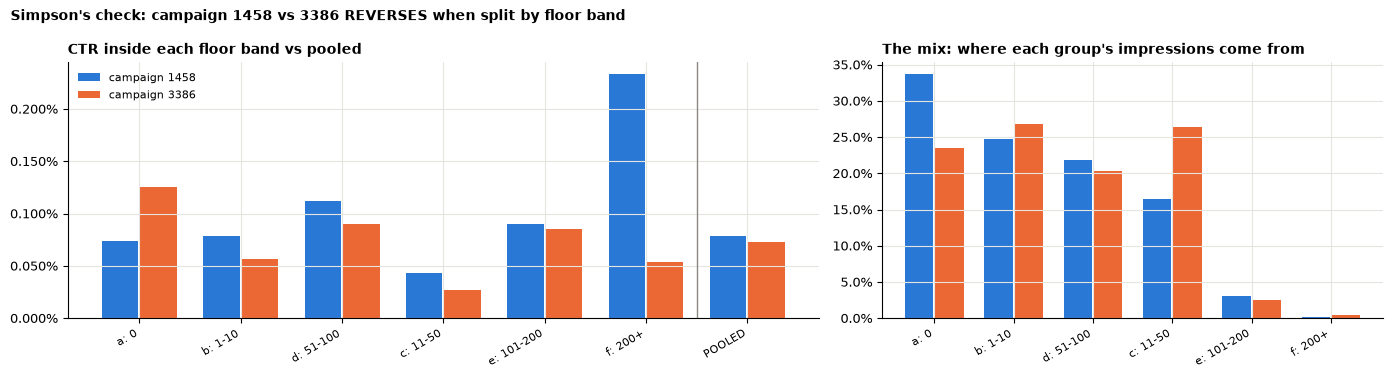

In [10]:
# CELL 9: pick and explain the showcase
cands = []
for dim, (a, b, r) in keep1.items():
    cands.append(("scan1", f"{dim.replace('_', ' ')} {a} vs {b}", "campaign", r, dim, a, b))
for (ca, cb, dim), r in keep2.items():
    cands.append(("scan2", f"campaign {ca} vs {cb}", dim.replace("_", " "), r, dim, ca, cb))
sig = [c for c in cands if c[3]["significant_reversal"]]
rev = [c for c in cands if c[3]["reversal"]]
if sig:
    pick = max(sig, key=lambda c: abs(c[3]["agg_diff_pp"]))
elif rev:
    pick = max(rev, key=lambda c: abs(c[3]["agg_diff_pp"]))
else:
    pick = max(cands, key=lambda c: abs(c[3]["within_diff_pp"] - c[3]["agg_diff_pp"]) / max(abs(c[3]["agg_diff_pp"]), 1e-9))
kind, title, strat_name, R, dim, A_, B_ = pick
t = R["detail"].copy()
t["rate_A"], t["rate_B"] = t.kA / t.nA, t.kB / t.nB
t["share_of_A"], t["share_of_B"] = t.nA / t.nA.sum(), t.nB / t.nB.sum()
t = t.sort_values("nA", ascending=False)
labelA = f"{dim.replace('_', ' ')} {A_}" if kind == "scan1" else f"campaign {A_}"
labelB = f"{dim.replace('_', ' ')} {B_}" if kind == "scan1" else f"campaign {B_}"
display(Markdown(f"**{title}, split by {strat_name}:** pooled {R['agg_rel']:+.0%} (p = {R['agg_p']:.2g}), within "
                 f"{strat_name}s {R['within_rel']:+.0%} (CMH p = {R['cmh_p']:.2g}). "
                 + ("**The direction reverses.**" if R["reversal"] else "Same direction (no reversal).")))
display(t[["stratum", "nA", "kA", "rate_A", "share_of_A", "nB", "kB", "rate_B", "share_of_B"]]
        .style.format({"nA": "{:,.0f}", "kA": "{:,.0f}", "nB": "{:,.0f}", "kB": "{:,.0f}", "rate_A": "{:.3%}",
                       "rate_B": "{:.3%}", "share_of_A": "{:.1%}", "share_of_B": "{:.1%}"}).hide(axis="index"))

if plt:
    show = t.head(10)
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
    x = np.arange(len(show) + 1)
    ra = list(show.rate_A) + [R["agg_rate_A"]]
    rb = list(show.rate_B) + [R["agg_rate_B"]]
    axes[0].bar(x - 0.19, ra, width=0.36, color=BLUE, label=str(labelA))
    axes[0].bar(x + 0.19, rb, width=0.36, color=ORANGE, label=str(labelB))
    axes[0].axvline(len(show) - 0.5, color=GREY, lw=1)
    axes[0].set_xticks(x, [str(s)[:12] for s in show.stratum] + ["POOLED"], rotation=30, ha="right", fontsize=8)
    axes[0].yaxis.set_major_formatter(mt.PercentFormatter(1.0, decimals=3))
    axes[0].set_title(f"CTR inside each {strat_name} vs pooled")
    axes[0].legend(frameon=False, fontsize=8)
    xs = np.arange(len(show))
    axes[1].bar(xs - 0.19, show.share_of_A, width=0.36, color=BLUE)
    axes[1].bar(xs + 0.19, show.share_of_B, width=0.36, color=ORANGE)
    axes[1].set_xticks(xs, [str(s)[:12] for s in show.stratum], rotation=30, ha="right", fontsize=8)
    axes[1].yaxis.set_major_formatter(mt.PercentFormatter(1.0))
    axes[1].set_title("The mix: where each group's impressions come from")
    fig.suptitle(f"Simpson's check: {title} " + ("REVERSES" if R["reversal"] else "does not reverse")
                 + f" when split by {strat_name}", x=0.01, ha="left", fontweight="bold", fontsize=10)
    fig.tight_layout()
    save(fig, "09_simpson")
    plt.show()

## Findings

Generated from the numbers above.

In [11]:
# CELL 10: findings + story candidates
n1, n2 = len(SCAN1), len(SCAN2)
F = [f"**Segments, pooled vs within campaign:** {n1} comparisons; {int(SCAN1.reversal.sum())} reverse direction "
     f"({int(SCAN1.significant_reversal.sum())} significantly).",
     f"**Campaign vs campaign, overall vs within segments:** {n2} comparisons; {int(SCAN2.reversal.sum())} reverse "
     f"direction ({int(SCAN2.significant_reversal.sum())} significantly)."]
F.append(f"**Clearest case: {title}, split by {strat_name}.** Pooled CTR {R['agg_rate_A']:.3%} vs {R['agg_rate_B']:.3%} "
         f"({R['agg_rel']:+.0%}, p = {R['agg_p']:.2g}); within {strat_name}s the weighted difference is "
         f"{R['within_rel']:+.0%} (CMH p = {R['cmh_p']:.2g}), agreeing in {R['strata_agreeing_with_within']} of "
         f"{R['strata']} {strat_name}s. "
         + ("**The direction reverses**: the pooled number reflects the mix, not the comparison." if R["reversal"]
            else "The direction holds, so this pooled comparison can be trusted."))
F.append("**Rule for the dashboard and the daily report:** compare segments within one campaign by default, and "
         "label pooled views as such. Before claiming that a segment or campaign is better, check the split.")
display(Markdown("\n".join(f"{i}. {t}" for i, t in enumerate(F, 1))))
p_conf = R["cmh_p"]   # the within-group difference is the one we act on
save_story("09_simpsons_check", [{
    "title": (f"Simpson's paradox: {title} flips when split by {strat_name}" if R["reversal"]
              else f"No Simpson's paradox in {title}: the pooled comparison holds when split by {strat_name}"),
    "number": f"pooled {R['agg_rel']:+.0%} (p = {R['agg_p']:.2g}) vs within {strat_name}s {R['within_rel']:+.0%} "
              f"(CMH p = {R['cmh_p']:.2g}); {int(SCAN1.reversal.sum() + SCAN2.reversal.sum())} of {n1 + n2} comparisons reverse",
    "chart": "09_simpson.png", "confidence": conf_from_p(p_conf),
    "meaning": ("Pooled numbers can point budget the wrong way here. Always compare within a campaign, or adjust for the mix."
                if R["reversal"] else
                "Pooled comparisons are safe for this dimension. Still compare within a campaign by default."),
}])

1. **Segments, pooled vs within campaign:** 9 comparisons; 0 reverse direction (0 significantly).
2. **Campaign vs campaign, overall vs within segments:** 90 comparisons; 15 reverse direction (0 significantly).
3. **Clearest case: campaign 1458 vs 3386, split by floor band.** Pooled CTR 0.079% vs 0.072% (+9%, p = 0.0038); within floor bands the weighted difference is -0% (CMH p = 0.94), agreeing in 1 of 6 floor bands. **The direction reverses**: the pooled number reflects the mix, not the comparison.
4. **Rule for the dashboard and the daily report:** compare segments within one campaign by default, and label pooled views as such. Before claiming that a segment or campaign is better, check the split.

Saved 1 story candidate(s) to reports/findings/09_simpsons_check.json
